# 05 - Evaluate the Farm A LSTM model

This notebook measures how the trained model performs on the held-out **prediction** windows. It does not train the model or change its threshold.

Run `03_feature_engineering.ipynb` and `04_train_model.ipynb` first. The results are useful for a project demo, but labels belong to whole events and are repeated across that event's windows, so window metrics are an initial estimate.


## 1. Load the saved model and prediction data

This notebook loads the model, scaler, threshold, prediction windows, and their event labels. It applies the scaler learned from training data, then measures reconstruction error.


In [13]:
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)
from IPython.display import display

cwd = Path.cwd()
PROJECT_ROOT = next(
    (p for p in (cwd, *cwd.parents)
     if (p / "data/processed/farm_a/features/farm_a_lstm_windows.npz").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run 03_feature_engineering.ipynb first")

FEATURE_DIR = PROJECT_ROOT / "data/processed/farm_a/features"
MODEL_DIR = PROJECT_ROOT / "models/farm_a"
WINDOW_FILE = FEATURE_DIR / "farm_a_lstm_windows.npz"
WINDOW_META_FILE = FEATURE_DIR / "window_metadata.csv"
MODEL_FILE = MODEL_DIR / "lstm_autoencoder.pt"
SCALER_FILE = MODEL_DIR / "scaler.joblib"
for path in [WINDOW_FILE, WINDOW_META_FILE, MODEL_FILE, SCALER_FILE]:
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}. Run the earlier notebooks first.")

sys.path.insert(0, str(PROJECT_ROOT))
from src.model import NormalLSTMAutoencoder

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bundle = np.load(WINDOW_FILE)
X_prediction_raw = bundle["X_prediction"].astype(np.float32)
y_prediction = bundle["y_prediction"].astype(np.int8)
feature_names = bundle["feature_names"].astype(str).tolist()
window_size = int(bundle["window_size"])
window_meta = pd.read_csv(WINDOW_META_FILE, parse_dates=["start_time", "end_time"])
pred_meta = window_meta.loc[window_meta.partition.eq("prediction")].sort_values("window_index").reset_index(drop=True)

if X_prediction_raw.ndim != 3 or X_prediction_raw.shape[1] != window_size or X_prediction_raw.shape[2] != len(feature_names):
    raise ValueError(f"Unexpected prediction data shape: {X_prediction_raw.shape}")
if not np.isfinite(X_prediction_raw).all():
    raise ValueError("Prediction windows contain non-finite sensor values")
if len(y_prediction) != len(X_prediction_raw) or len(pred_meta) != len(X_prediction_raw):
    raise ValueError("Prediction data, labels, and metadata have different row counts")
if not np.array_equal(pred_meta.window_index.to_numpy(), np.arange(len(pred_meta))):
    raise ValueError("Prediction metadata does not align with the saved window order")
if not np.array_equal(pred_meta.target.astype(int).to_numpy(), y_prediction):
    raise ValueError("Prediction labels do not match the metadata")
if not set(np.unique(y_prediction)).issubset({0, 1}):
    raise ValueError("Prediction labels must be 0=normal or 1=anomaly")

checkpoint = torch.load(MODEL_FILE, map_location="cpu")
if checkpoint["feature_names"] != feature_names or int(checkpoint["window_size"]) != window_size:
    raise ValueError("Model feature order or window size does not match the prepared data")
scaler = joblib.load(SCALER_FILE)
model = NormalLSTMAutoencoder(
    n_features=int(checkpoint["n_features"]),
    hidden_size=int(checkpoint.get("hidden_size", 64)),
).to(DEVICE)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
threshold = float(checkpoint["threshold"])

print("Project:", PROJECT_ROOT)
print("Compute device:", DEVICE)
print("Prediction windows:", len(X_prediction_raw))
print("Labels (0=normal, 1=anomaly):", pd.Series(y_prediction).value_counts().sort_index().to_dict())
print(f"Threshold selected from validation: {float(checkpoint.get('threshold_quantile', float('nan'))):.1%} percentile = {threshold:.6f}")


Project: c:\Users\mohamad\Desktop\Predictive-Maintenance
Compute device: cpu
Prediction windows: 441
Labels (0=normal, 1=anomaly): {0: 223, 1: 218}
Threshold selected from validation: 90.0% percentile = 0.329109


## 2. Score prediction windows and calculate metrics

A larger reconstruction error means the sensor window looked less like the normal training data. We flag a window when its error is above the threshold selected in notebook 04.


Prediction-window metrics:


,metric,value
0,Average precision (PR-AUC),0.6402
1,ROC-AUC,0.6203
2,Accuracy,0.5669
3,Anomaly precision,0.7547
4,Anomaly recall,0.1835
5,Anomaly F1,0.2952


Classification report:


,precision,recall,f1-score,support
normal,0.5412,0.9417,0.6874,223.0000
anomaly,0.7547,0.1835,0.2952,218.0000
accuracy,0.5669,0.5669,0.5669,0.5669
macro avg,0.6480,0.5626,0.4913,441.0000
weighted avg,0.6468,0.5669,0.4935,441.0000


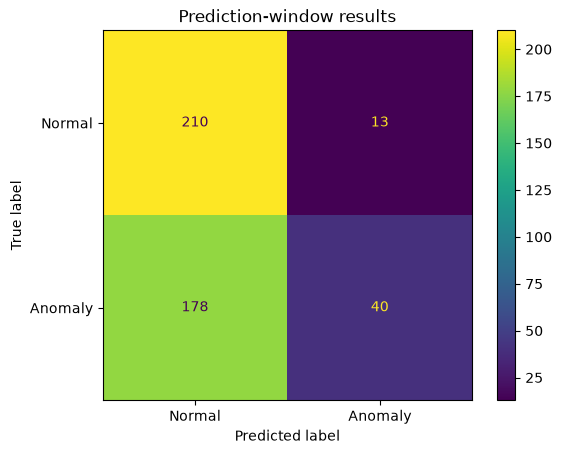

In [14]:
n_features = len(feature_names)
X_prediction = scaler.transform(
    X_prediction_raw.reshape(-1, n_features)
).reshape(X_prediction_raw.shape).astype(np.float32)
prediction_tensor = torch.from_numpy(X_prediction).to(DEVICE)
with torch.no_grad():
    prediction_scores = ((model(prediction_tensor) - prediction_tensor) ** 2).mean(dim=(1, 2)).cpu().numpy()
y_pred = (prediction_scores > threshold).astype(np.int8)

has_both_classes = len(np.unique(y_prediction)) == 2
metrics = pd.DataFrame({
    "metric": [
        "Average precision (PR-AUC)", "ROC-AUC", "Accuracy",
        "Anomaly precision", "Anomaly recall", "Anomaly F1",
    ],
    "value": [
        average_precision_score(y_prediction, prediction_scores) if has_both_classes else np.nan,
        roc_auc_score(y_prediction, prediction_scores) if has_both_classes else np.nan,
        accuracy_score(y_prediction, y_pred),
        precision_score(y_prediction, y_pred, zero_division=0),
        recall_score(y_prediction, y_pred, zero_division=0),
        f1_score(y_prediction, y_pred, zero_division=0),
    ],
})
metrics["value"] = metrics["value"].round(4)
print("Prediction-window metrics:")
display(metrics)

report = classification_report(
    y_prediction, y_pred, labels=[0, 1], target_names=["normal", "anomaly"],
    output_dict=True, zero_division=0,
)
report_df = pd.DataFrame(report).T
print("Classification report:")
display(report_df.round(4))

cm = confusion_matrix(y_prediction, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomaly"]).plot(values_format="d")
plt.title("Prediction-window results")
plt.show()


## 3. Summarize results by event

Window metrics count every window separately. Since an event can produce many similar windows, this table also gives one row per event. Its mean error is compared with the same validation threshold.


In [15]:
score_meta = pred_meta.copy()
score_meta["reconstruction_error"] = prediction_scores
score_meta["predicted_anomaly_window"] = y_pred == 1
event_scores = score_meta.groupby(
    ["event_id", "turbine_id", "event_label"], as_index=False
).agg(
    windows=("reconstruction_error", "size"),
    mean_error=("reconstruction_error", "mean"),
    anomaly_window_fraction=("predicted_anomaly_window", "mean"),
    overlapping_windows=("contains_cross_event_overlap", "sum"),
)
event_scores["target"] = event_scores.event_label.map({"normal": 0, "anomaly": 1})
event_scores["predicted_anomaly"] = (event_scores.mean_error > threshold).astype(int)
print("Event-level results (one row per event):")
display(event_scores.round(4))
if event_scores.target.nunique() == 2:
    print("Event-level ROC-AUC:", round(roc_auc_score(event_scores.target, event_scores.mean_error), 4))
print(
    "Prediction windows marked as overlapping another event's prediction timestamps:",
    int(pred_meta.contains_cross_event_overlap.sum()), "of", len(pred_meta),
)


Event-level results (one row per event):


,event_id,turbine_id,event_label,windows,mean_error,anomaly_window_fraction,overlapping_windows,target,predicted_anomaly
0,0,0,anomaly,26,0.2697,0.2692,26,1,0
1,3,10,normal,28,0.1535,0.0000,28,0,0
2,10,10,anomaly,11,0.2290,0.1818,11,1,0
3,13,21,normal,30,0.1318,0.0333,30,0,0
4,14,13,normal,16,0.1743,0.0625,16,0,0
5,17,10,normal,24,0.2041,0.1250,0,0,0
6,22,21,anomaly,11,0.1600,0.0909,11,1,0
7,24,0,normal,24,0.1337,0.0417,24,0,0
8,25,11,normal,21,0.1394,0.0476,21,0,0
9,26,0,anomaly,12,0.1416,0.0833,0,1,0


Event-level ROC-AUC: 0.8583
Prediction windows marked as overlapping another event's prediction timestamps: 335 of 441


## 4. Save evaluation results

This saves tables and a confusion-matrix image in `reports/farm_a/`. Save this notebook after running it too if you want the output cells preserved inside the notebook.


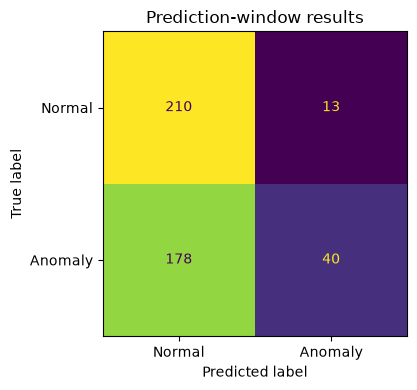

Saved evaluation tables and plot to: c:\Users\mohamad\Desktop\Predictive-Maintenance\reports\farm_a


In [16]:
REPORT_DIR = PROJECT_ROOT / "reports" / "farm_a"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

window_results = pred_meta[[
    "window_index", "event_id", "turbine_id", "event_label", "target",
    "start_time", "end_time", "contains_cross_event_overlap",
]].copy()
window_results["reconstruction_error"] = prediction_scores
window_results["predicted_anomaly"] = y_pred
metrics.to_csv(REPORT_DIR / "window_metrics.csv", index=False)
report_df.to_csv(REPORT_DIR / "classification_report.csv")
window_results.to_csv(REPORT_DIR / "prediction_window_scores.csv", index=False)
event_scores.to_csv(REPORT_DIR / "event_level_scores.csv", index=False)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomaly"]).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("Prediction-window results")
fig.tight_layout()
fig.savefig(REPORT_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved evaluation tables and plot to:", REPORT_DIR)


## How to read the results

- **Recall:** of the anomaly windows, how many did the model flag?
- **Precision:** of the windows it flagged, how many had anomaly labels?
- **False alarms:** normal-labeled windows that were flagged.
- **Event-level table:** a useful second view because labels describe whole events.

These are first project metrics, not proof that the model is ready for real turbine decisions. Review the event-level rows and the label limitations before drawing conclusions.
